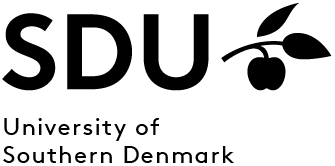
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

# Week 3 demo — Linear filters


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, exposure, filters, util

try:
    import oip
except Exception:
    oip = None

from scipy import ndimage

## 1. Point operation or neighbourhood operation?

So far, we have mainly considered **point operations**: the value of an output pixel depends only on the value of the corresponding input pixel.

Now imagine a different operation: each output pixel is calculated using the input pixel **and its eight immediate neighbours**.

**Think → pair → vote:**

1. If the value of one input pixel changes, how many output pixels could change in a point operation?
2. How many output pixels could change in this new neighbourhood operation?
3. Sketch the affected pixels.
4. What additional information would we need to specify exactly how the nine input pixels are combined?

YOUR ANSWER HERE

In [ ]:
image = oip.load_grey("coins", dtype=float)
oip.show_image(image, "Original")


## 2. Box filter: predict before viewing

For a normalized 3×3 box kernel:

- What happens in a constant region?
- What happens to an isolated bright pixel?
- What happens to a sharp edge?


In [ ]:
kernel = np.ones((3, 3), dtype=float) / 9
print(kernel)
print("kernel sum:", kernel.sum())

box = ndimage.correlate(image, kernel, mode="reflect")
oip.show_images(image,box)



## 3. Border handling on a controlled 1D-like image

**Prediction:** which boundary mode should create the strongest artificial discontinuity at the image edge: `constant`, `nearest`, `reflect`, or `wrap`?


In [ ]:
edge_test = np.tile(np.linspace(0.2, 1.0, 48), (24, 1))
modes = ["constant", "nearest", "reflect", "wrap"]
fig, axes = plt.subplots(1, len(modes), figsize=(14, 3))
for ax, mode in zip(axes, modes):
    out = ndimage.correlate(edge_test, kernel, mode=mode, cval=0.0)
    ax.imshow(out, cmap="gray", vmin=0, vmax=1)
    ax.set_title(mode)
    ax.axis("off")
plt.show()


## 4. Gaussian scale

**Prediction:** which structures are lost first when \(\sigma\) increases? Why is kernel size meaningless unless it is related to \(\sigma\)?


In [ ]:
sigmas = [0.5, 1, 2, 4]
fig, axes = plt.subplots(1, len(sigmas), figsize=(14, 4))
for ax, sigma in zip(axes, sigmas):
    out = ndimage.gaussian_filter(image, sigma=sigma, mode="reflect")
    ax.imshow(out, cmap="gray")
    ax.set_title(f"sigma={sigma}")
    ax.axis("off")
plt.show()


## 5. Correlation versus convolution

First use a symmetric Gaussian-like kernel. Then use an antisymmetric derivative kernel. **Predict before running:** for which one will the operations differ?


In [ ]:
symmetric = np.array([[1,2,1],[2,4,2],[1,2,1]], dtype=float) / 16
asymmetric = np.array([[0,0,0],[-1,0,1],[0,0,0]], dtype=float)

for name, k in [("symmetric", symmetric), ("derivative", asymmetric)]:
    corr = ndimage.correlate(image, k, mode="reflect")
    conv = ndimage.convolve(image, k, mode="reflect")
    print(name, "max |corr-conv| =", np.max(np.abs(corr-conv)),
          "max |corr+conv| =", np.max(np.abs(corr+conv)))


## 6. Separability

A Gaussian can be applied as successive 1D filters. Predict both the numerical difference and the theoretical scaling of the operation count before running.


In [ ]:
sigma = 3
full = ndimage.gaussian_filter(image, sigma=sigma, mode="reflect")
sep = ndimage.gaussian_filter1d(image, sigma=sigma, axis=0, mode="reflect")
sep = ndimage.gaussian_filter1d(sep, sigma=sigma, axis=1, mode="reflect")
print("max difference:", np.max(np.abs(full-sep)))


## 7. Laplacian: zero sum and noise sensitivity

The kernel below has a negative centre coefficient, so it approximates
$\nabla^2 I$ with this sign convention.

**Prediction:**

- What should a zero-sum kernel return in a constant region?
- Why should the response become stronger when high-frequency noise is added?


In [ ]:
lap_kernel = np.array([[0,1,0],[1,-4,1],[0,1,0]], dtype=float)
rng = np.random.default_rng(1)
noisy = image + rng.normal(0, 0.02, image.shape)
lap = ndimage.correlate(image, lap_kernel, mode="reflect")
lap_noisy = ndimage.correlate(noisy, lap_kernel, mode="reflect")
print("kernel sum:", lap_kernel.sum())
print("response std, original:", np.std(lap))
print("response std, noisy:   ", np.std(lap_noisy))


## 8. Laplacian sharpening and unsharp masking

For the negative-centre Laplacian kernel used above, Laplacian sharpening is

$$
I_{\mathrm{sharp}} = I-w(H_L*I).
$$

Unsharp masking instead extracts detail using a Gaussian blur:

$$
M=I-G_\sigma*I,
\qquad
I_{\mathrm{sharp}}=I+wM.
$$

**Predict before running:**

1. Why is the Laplacian response subtracted for this kernel sign?
2. How will increasing $\sigma$ change the scale of enhanced structures?
3. Why is $I-w(G_\sigma*I)$ not the unsharp-mask result?


In [ ]:
lap_amount = 0.25
unsharp_amount = 1.5
sigma = 2.0

lap_response = ndimage.correlate(
    image, lap_kernel, mode="reflect"
)
lap_sharp = image - lap_amount * lap_response

blurred = ndimage.gaussian_filter(
    image, sigma=sigma, mode="reflect"
)
detail_mask = image - blurred
unsharp = image + unsharp_amount * detail_mask

# This is deliberately included as a contrast: it is not unsharp masking.
subtract_blur = image - unsharp_amount * blurred

results = [
    ("original", image),
    ("Laplacian sharpening", lap_sharp),
    ("unsharp masking", unsharp),
    (r"$I-w(G_\sigma*I)$", subtract_blur),
]

fig, axes = plt.subplots(1, len(results), figsize=(16, 4))
for ax, (title, result) in zip(axes, results):
    ax.imshow(np.clip(result, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

for title, result in results:
    print(
        f"{title:24s} mean={result.mean():.3f}, "
        f"range=({result.min():.3f}, {result.max():.3f})"
    )


## Exit question

Without running code, what can you infer about a linear spatial filter from
only its kernel?

<details>
Try to mention coefficient sum, symmetry, sign pattern, spatial extent, and
possible separability. Then explain why Laplacian sharpening and unsharp
masking both enhance detail but are not the same operation.
</details>
